# ECE 3715 Mini-Project 3

## Random Vectors and the Multivariate Gaussian
Professor: Dr. Nir Regev

Team Members: Brandon Chie, Octavio Reyna, William Hsu

Start Date: November 14, 2026

Due Date: November 23, 2026

## Objective
Use joint, marginal and conditional densities, covariance matrices, linear transformations and the multivariate Gaussian to study several correlated random variables at once. We will use eigendecomposition and whitening to remove correlation, and then fuse two sensors with correlated noise into one linear MMSE estimate.

In [1]:
import time #Used for the timer function
import numpy #Used for easy array manipulation functions & RNG
import scipy #Used for numerical integration and the multivariate normal check
import matplotlib.pyplot as plt #Used for plotting graphs
import mp3lib as func #Functions from mp3lib.py file

T_START = time.time()     #Timer begins for total notebook time

SEED = 295929189          #Drawn 2026-11-14, do not change
rng = numpy.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

In [2]:
#Handcheckable Test
#Assert confirms that the comparison is true, if not assert error will pop up

#Sample Mean and Covariance Test
#Three samples of two variables, the mean is [2, 4] and the covariance can be done by hand
X_test = numpy.array([[1, 2], [2, 4], [3, 6]])
mean_test, cov_test = func.sample_mean_cov(X_test)
assert numpy.allclose(mean_test, [2, 4])
assert numpy.allclose(cov_test, [[1, 2], [2, 4]]) #Var(x) = 1, Var(y) = 4, Cov = 2
print(f"Sample Mean Test:       {mean_test}")
print(f"Sample Covariance Test: {cov_test[0]}")
print(f"                        {cov_test[1]}")

#Valid Covariance Test
#Identity matrix is valid, a non symmetric matrix is not, and [[1, 2], [2, 1]] has eigenvalues 3 and -1 so it is not
assert func.is_valid_covariance(numpy.eye(2)) == True
assert func.is_valid_covariance([[1, 2], [0, 1]]) == False
assert func.is_valid_covariance([[1, 2], [2, 1]]) == False
print("\nValid Covariance Test:")
print(f"Identity:              {func.is_valid_covariance(numpy.eye(2))}")
print(f"Non symmetric:         {func.is_valid_covariance([[1, 2], [0, 1]])}")
print(f"Negative eigenvalue:   {func.is_valid_covariance([[1, 2], [2, 1]])}")

#Gaussian PDF Test
#For a 2D standard Gaussian the density at the mean is 1/(2pi)
assert numpy.isclose(func.gaussian_pdf([0, 0], [0, 0], numpy.eye(2)), 1 / (2 * numpy.pi))
print("\nGaussian PDF Test:")
print(f"f(0, 0): {func.gaussian_pdf([0, 0], [0, 0], numpy.eye(2)):.6f}   1/(2pi): {1 / (2 * numpy.pi):.6f}")

#Whitening Matrix Test
#For Sigma = diag(4, 9) the whitening matrix should give W Sigma W^T = I
Sigma_test = numpy.diag([4.0, 9.0])
W_test = func.whitening_matrix(Sigma_test)
assert numpy.allclose(W_test @ Sigma_test @ W_test.T, numpy.eye(2))
print("\nWhitening Test:")
print(f"W Sigma W^T: {(W_test @ Sigma_test @ W_test.T)[0]}")
print(f"             {(W_test @ Sigma_test @ W_test.T)[1]}")

#LMMSE Weights Test
#Sigma_xx = 2I and Sigma_sx = [1, 1] should give equal weights of 0.5
assert numpy.allclose(func.lmmse_weights(2 * numpy.eye(2), [1, 1]), [0.5, 0.5])
print("\nLMMSE Weights Test:")
print(f"w: {func.lmmse_weights(2 * numpy.eye(2), [1, 1])}")

print("\nAll functions work as expected!")

Sample Mean Test:       [2. 4.]
Sample Covariance Test: [1. 2.]
                        [2. 4.]

Valid Covariance Test:
Identity:              True
Non symmetric:         False
Negative eigenvalue:   False

Gaussian PDF Test:
f(0, 0): 0.159155   1/(2pi): 0.159155

Whitening Test:
W Sigma W^T: [1. 0.]
             [0. 1.]

LMMSE Weights Test:
w: [0.5 0.5]

All functions work as expected!


## Step 1: Two Variables at Once

**Objective:** Find the joint, marginal and conditional densities of two random variables by hand and confirm them numerically.

$$f_{XY}(x,y)=x+y \qquad 0\leq x\leq 1,\; 0\leq y\leq 1$$

**Process:** We will verify the density, find the marginals, the conditional density and the moments by hand, then check each one with quadrature. Then we will generate $10^6$ samples by rejection sampling and compare the sample statistics with the exact values.

### Valid Density

Non negative:

$$x\geq 0,\; y\geq 0 \;\Rightarrow\; f_{XY}(x,y)=x+y\geq 0$$

Integrates to 1:

$$\int_0^1\int_0^1 (x+y)\,dx\,dy=\int_0^1\left[\frac{x^2}{2}+xy\right]_0^1dy$$

$$=\int_0^1\left(\frac{1}{2}+y\right)dy=\left[\frac{y}{2}+\frac{y^2}{2}\right]_0^1$$

$$=\frac{1}{2}+\frac{1}{2}=1$$

### Marginal Densities

Marginal of X:

$$f_X(x)=\int_0^1 (x+y)\,dy=\left[xy+\frac{y^2}{2}\right]_0^1$$

$$f_X(x)=x+\frac{1}{2} \qquad 0\leq x\leq 1$$

Marginal of Y:

$$f_Y(y)=\int_0^1 (x+y)\,dx=\left[\frac{x^2}{2}+xy\right]_0^1$$

$$f_Y(y)=y+\frac{1}{2} \qquad 0\leq y\leq 1$$

At $x=0.3$:

$$f_X(0.3)=0.3+0.5=0.8$$

### Conditional Density of Y given X = x

$$f_{Y|X}(y\mid x)=\frac{f_{XY}(x,y)}{f_X(x)}=\frac{x+y}{x+\frac{1}{2}}$$

At $x=0.3$:

$$f_{Y|X}(y\mid 0.3)=\frac{0.3+y}{0.8}$$

Integrates to 1:

$$\int_0^1\frac{0.3+y}{0.8}\,dy=\frac{1}{0.8}\left[0.3y+\frac{y^2}{2}\right]_0^1=\frac{0.3+0.5}{0.8}=1$$

### Moments

Mean:

$$E[X]=\int_0^1 x\left(x+\frac{1}{2}\right)dx=\left[\frac{x^3}{3}+\frac{x^2}{4}\right]_0^1=\frac{1}{3}+\frac{1}{4}$$

$$E[X]=E[Y]=\frac{7}{12}=0.583333$$

Variance:

$$E[X^2]=\int_0^1 x^2\left(x+\frac{1}{2}\right)dx=\left[\frac{x^4}{4}+\frac{x^3}{6}\right]_0^1=\frac{1}{4}+\frac{1}{6}=\frac{5}{12}$$

$$\text{Var}(X)=E[X^2]-E[X]^2=\frac{5}{12}-\frac{49}{144}=\frac{60}{144}-\frac{49}{144}$$

$$\text{Var}(X)=\frac{11}{144}=0.0763889$$

E[XY]:

$$E[XY]=\int_0^1\int_0^1 xy(x+y)\,dx\,dy=\int_0^1\int_0^1 x^2y\,dx\,dy+\int_0^1\int_0^1 xy^2\,dx\,dy$$

$$=\frac{1}{3}\cdot\frac{1}{2}+\frac{1}{2}\cdot\frac{1}{3}=\frac{1}{6}+\frac{1}{6}$$

$$E[XY]=\frac{1}{3}$$

Covariance:

$$\text{Cov}(X,Y)=E[XY]-E[X]E[Y]=\frac{1}{3}-\frac{49}{144}=\frac{48}{144}-\frac{49}{144}$$

$$\text{Cov}(X,Y)=-\frac{1}{144}=-0.00694444$$

Correlation coefficient:

$$\rho=\frac{\text{Cov}(X,Y)}{\sqrt{\text{Var}(X)\text{Var}(Y)}}=\frac{-1/144}{11/144}$$

$$\rho=-\frac{1}{11}=-0.0909091$$

In [3]:
#Step 1: Two variables at once

#Joint density f(x, y) = x + y on the unit square, 0 everywhere else
def joint_pdf(x, y):
    x = numpy.asarray(x, dtype=float)
    y = numpy.asarray(y, dtype=float)
    inside = (x >= 0) & (x <= 1) & (y >= 0) & (y <= 1)
    return numpy.where(inside, x + y, 0)

#Analytical marginal of X: f_X(x) = x + 1/2
def marginal_x(x):
    return x + 0.5

#Analytical marginal of Y: f_Y(y) = y + 1/2
def marginal_y(y):
    return y + 0.5

#Analytical conditional of Y given X = x: f(y|x) = (x + y)/(x + 1/2)
def conditional_y_given_x(y, x):
    return (x + y) / (x + 0.5)

#Part 1: Valid density

#2D quadrature of the joint density over the unit square
#dblquad integrates func(y, x) where y is the inner variable
total_probability = scipy.integrate.dblquad(lambda y, x: x + y, 0, 1, 0, 1)[0]

#Grid of x and y values used for the numerical marginals and the plots
x_grid = numpy.linspace(0, 1, 1001)
y_grid = numpy.linspace(0, 1, 1001)
X_grid, Y_grid = numpy.meshgrid(x_grid, y_grid, indexing="ij") #X_grid[i, j] = x_i and Y_grid[i, j] = y_j
joint_grid = joint_pdf(X_grid, Y_grid)

print("Part 1: Valid Density")
print(f"Smallest value of f(x, y) on the grid: {joint_grid.min():.6f}")
print(f"2D quadrature of f(x, y):              {total_probability:.10f}")
print(f"Difference from 1:                     {abs(total_probability - 1):.2e}")

#Part 2: Marginals

#Integrate the joint density over y (axis 1) to get f_X, and over x (axis 0) to get f_Y
fx_numerical = scipy.integrate.simpson(joint_grid, x=y_grid, axis=1)
fy_numerical = scipy.integrate.simpson(joint_grid, x=x_grid, axis=0)

#Largest difference between the numerical and analytical marginals
fx_max_diff = numpy.max(numpy.abs(fx_numerical - marginal_x(x_grid)))
fy_max_diff = numpy.max(numpy.abs(fy_numerical - marginal_y(y_grid)))

print("\nPart 2: Marginals")
print(f"Largest difference f_X numerical vs analytical: {fx_max_diff:.2e}")
print(f"Largest difference f_Y numerical vs analytical: {fy_max_diff:.2e}")
print(f"f_X(0.3) analytical: {marginal_x(0.3):.6f}   numerical: {fx_numerical[300]:.6f}")

#Part 3: Conditional density at x = 0.3

x0 = 0.3

#Analytical conditional on the y grid
conditional_analytical = conditional_y_given_x(y_grid, x0)

#Numerical conditional: joint density along x = 0.3 divided by the numerical marginal at x = 0.3
fx0_numerical = scipy.integrate.simpson(joint_pdf(x0, y_grid), x=y_grid)
conditional_numerical = joint_pdf(x0, y_grid) / fx0_numerical

#Integral of the conditional density over y
conditional_integral = scipy.integrate.quad(lambda y: conditional_y_given_x(y, x0), 0, 1)[0]

print("\nPart 3: Conditional Density at x = 0.3")
print(f"Integral of f(y | 0.3):                      {conditional_integral:.10f}")
print(f"Largest difference numerical vs analytical:  {numpy.max(numpy.abs(conditional_numerical - conditional_analytical)):.2e}")
print(f"f(y | 0.3) at y = 0: {conditional_y_given_x(0, x0):.4f}   at y = 1: {conditional_y_given_x(1, x0):.4f}")

#Part 4: Moments

#Hand calculated values
E_X_exact = 7 / 12
E_Y_exact = 7 / 12
E_XY_exact = 1 / 3
Var_X_exact = 11 / 144
Cov_XY_exact = -1 / 144
rho_exact = -1 / 11

#Quadrature values, each one integrates g(x, y) * f(x, y) over the unit square
E_X_quad = scipy.integrate.dblquad(lambda y, x: x * (x + y), 0, 1, 0, 1)[0]
E_Y_quad = scipy.integrate.dblquad(lambda y, x: y * (x + y), 0, 1, 0, 1)[0]
E_XY_quad = scipy.integrate.dblquad(lambda y, x: x * y * (x + y), 0, 1, 0, 1)[0]
E_X2_quad = scipy.integrate.dblquad(lambda y, x: x**2 * (x + y), 0, 1, 0, 1)[0]
E_Y2_quad = scipy.integrate.dblquad(lambda y, x: y**2 * (x + y), 0, 1, 0, 1)[0]

#Variance, covariance and correlation from the quadrature moments
Var_X_quad = E_X2_quad - E_X_quad**2
Var_Y_quad = E_Y2_quad - E_Y_quad**2
Cov_XY_quad = E_XY_quad - E_X_quad * E_Y_quad
rho_quad = Cov_XY_quad / numpy.sqrt(Var_X_quad * Var_Y_quad)

#Array of hand calculated values
exact_moments = numpy.array([E_X_exact, E_Y_exact, E_XY_exact, Var_X_exact, Cov_XY_exact, rho_exact])

#Array of quadrature values
quad_moments = numpy.array([E_X_quad, E_Y_quad, E_XY_quad, Var_X_quad, Cov_XY_quad, rho_quad])

#Difference between the quadrature and hand calculated values
diff_moments = numpy.abs(quad_moments - exact_moments)

print("\nPart 4: Moments")
print("Quantity      By Hand      Exact          Quadrature     Difference")
print(f"E[X]:         7/12         {exact_moments[0]:<15.6f}{quad_moments[0]:<15.6f}{diff_moments[0]:.2e}")
print(f"E[Y]:         7/12         {exact_moments[1]:<15.6f}{quad_moments[1]:<15.6f}{diff_moments[1]:.2e}")
print(f"E[XY]:        1/3          {exact_moments[2]:<15.6f}{quad_moments[2]:<15.6f}{diff_moments[2]:.2e}")
print(f"Var(X):       11/144       {exact_moments[3]:<15.6f}{quad_moments[3]:<15.6f}{diff_moments[3]:.2e}")
print(f"Cov(X,Y):     -1/144       {exact_moments[4]:<15.6f}{quad_moments[4]:<15.6f}{diff_moments[4]:.2e}")
print(f"rho:          -1/11        {exact_moments[5]:<15.6f}{quad_moments[5]:<15.6f}{diff_moments[5]:.2e}")
print(f"\nLargest difference between quadrature and hand values: {diff_moments.max():.2e}")

Part 1: Valid Density
Smallest value of f(x, y) on the grid: 0.000000
2D quadrature of f(x, y):              1.0000000000
Difference from 1:                     0.00e+00

Part 2: Marginals
Largest difference f_X numerical vs analytical: 4.44e-16
Largest difference f_Y numerical vs analytical: 1.11e-15
f_X(0.3) analytical: 0.800000   numerical: 0.800000

Part 3: Conditional Density at x = 0.3
Integral of f(y | 0.3):                      1.0000000000
Largest difference numerical vs analytical:  0.00e+00
f(y | 0.3) at y = 0: 0.3750   at y = 1: 1.6250

Part 4: Moments
Quantity      By Hand      Exact          Quadrature     Difference
E[X]:         7/12         0.583333       0.583333       1.11e-16
E[Y]:         7/12         0.583333       0.583333       1.11e-16
E[XY]:        1/3          0.333333       0.333333       1.11e-16
Var(X):       11/144       0.076389       0.076389       5.55e-17
Cov(X,Y):     -1/144       -0.006944      -0.006944      1.91e-16
rho:          -1/11        -0.0

### Rejection Sampling

We propose points uniformly on the unit square and accept each one if

$$U\cdot M\leq f_{XY}(x,y)$$

- $U$ = uniform random number between 0 and 1
- $M$ = bounding constant

We chose $M=2$ because the largest value of $x+y$ on the unit square is 2 at $(1,1)$. A larger $M$ would still work but would reject more points and make the notebook slower. The acceptance rate should be

$$P(\text{accept})=\frac{1}{M}=\frac{1}{2}$$

so we propose $2.2\times10^6$ points to get at least $10^6$ samples.

For the standard errors we use $SE=\frac{s}{\sqrt{N}}$, except for $\rho$, where we use batch means (100 batches of $10^4$ samples) since $\rho$ is not a simple average.

In [4]:
#Part 5: Rejection sampling

N_1 = 10**6 #One million samples

#Bounding constant, the density x + y is largest at (1, 1) where it equals 2
M = 2

#Number of proposals, the acceptance rate is 1/M = 0.5 so we propose a little more than 2 million
N_proposals = int(2.2 * N_1)

#Proposals from the uniform density on the unit square
x_proposals = rng1.random(N_proposals)
y_proposals = rng1.random(N_proposals)

#Uniform numbers used to decide if each proposal is accepted
u_accept = rng1.random(N_proposals)

#Accept the proposal if U * M is less than or equal to f(x, y)
accepted = u_accept * M <= joint_pdf(x_proposals, y_proposals)

#Acceptance rate and its standard error
acceptance_rate = accepted.mean()
acceptance_se = numpy.sqrt(acceptance_rate * (1 - acceptance_rate) / N_proposals)

#Makes sure that we have at least one million accepted samples, if not assert error will pop up
assert accepted.sum() >= N_1

#Keeps the first one million accepted samples
x_samples = x_proposals[accepted][:N_1]
y_samples = y_proposals[accepted][:N_1]

print("Rejection Sampling")
print(f"Proposals:          {N_proposals}")
print(f"Accepted:           {accepted.sum()}")
print(f"Acceptance rate:    {acceptance_rate:.5f}   Standard Error: {acceptance_se:.5f}")
print(f"Expected rate 1/M:  {1 / M}")

#Sample statistics
E_X_sim = numpy.mean(x_samples)
E_Y_sim = numpy.mean(y_samples)
E_XY_sim = numpy.mean(x_samples * y_samples)
Var_X_sim = numpy.var(x_samples)
Cov_XY_sim = numpy.mean((x_samples - E_X_sim) * (y_samples - E_Y_sim))
rho_sim = numpy.corrcoef(x_samples, y_samples)[0, 1]

#Standard errors
#For a sample mean the standard error is the standard deviation divided by sqrt(N)
#Var and Cov are also sample means of (x - mean)^2 and (x - mean)(y - mean), so the same formula works
se_E_X = numpy.std(x_samples) / numpy.sqrt(N_1)
se_E_Y = numpy.std(y_samples) / numpy.sqrt(N_1)
se_E_XY = numpy.std(x_samples * y_samples) / numpy.sqrt(N_1)
se_Var_X = numpy.std((x_samples - E_X_sim)**2) / numpy.sqrt(N_1)
se_Cov_XY = numpy.std((x_samples - E_X_sim) * (y_samples - E_Y_sim)) / numpy.sqrt(N_1)

#The correlation is not a simple sample mean, and (1 - rho^2)/sqrt(N - 2) only holds for Gaussian data,
#so we use batch means: split the samples into 100 batches of 10^4, find rho in each batch,
#and the standard error is the standard deviation of the batch values divided by sqrt(100)
n_batches = 100
x_batches = x_samples.reshape(n_batches, -1)
y_batches = y_samples.reshape(n_batches, -1)
rho_batches = numpy.array([numpy.corrcoef(x_batches[i], y_batches[i])[0, 1] for i in range(n_batches)])
se_rho = numpy.std(rho_batches, ddof=1) / numpy.sqrt(n_batches)

#Array of sample values
sim_moments = numpy.array([E_X_sim, E_Y_sim, E_XY_sim, Var_X_sim, Cov_XY_sim, rho_sim])

#Array of standard errors
standard_errors = numpy.array([se_E_X, se_E_Y, se_E_XY, se_Var_X, se_Cov_XY, se_rho])

#Difference between the sample and exact values
diff_sim = numpy.abs(sim_moments - exact_moments)

#Checks if the difference is within 3 standard errors
within_three_SE = diff_sim <= 3 * standard_errors

print("\nQuantity      Exact          Sample         Difference     SE             Within 3 SE")
print(f"E[X]:         {exact_moments[0]:<15.6f}{sim_moments[0]:<15.6f}{diff_sim[0]:<15.6f}{standard_errors[0]:<15.6f}{within_three_SE[0]}")
print(f"E[Y]:         {exact_moments[1]:<15.6f}{sim_moments[1]:<15.6f}{diff_sim[1]:<15.6f}{standard_errors[1]:<15.6f}{within_three_SE[1]}")
print(f"E[XY]:        {exact_moments[2]:<15.6f}{sim_moments[2]:<15.6f}{diff_sim[2]:<15.6f}{standard_errors[2]:<15.6f}{within_three_SE[2]}")
print(f"Var(X):       {exact_moments[3]:<15.6f}{sim_moments[3]:<15.6f}{diff_sim[3]:<15.6f}{standard_errors[3]:<15.6f}{within_three_SE[3]}")
print(f"Cov(X,Y):     {exact_moments[4]:<15.6f}{sim_moments[4]:<15.6f}{diff_sim[4]:<15.6f}{standard_errors[4]:<15.6f}{within_three_SE[4]}")
print(f"rho:          {exact_moments[5]:<15.6f}{sim_moments[5]:<15.6f}{diff_sim[5]:<15.6f}{standard_errors[5]:<15.6f}{within_three_SE[5]}")

#Conditional mean of Y given X = x, used for Part 6
#E[Y | X = x] = (x/2 + 1/3)/(x + 1/2)
def conditional_mean_y(x):
    return (x / 2 + 1 / 3) / (x + 0.5)

#Sample mean of Y when X is small (below 0.1) and when X is large (above 0.9)
y_small_x = y_samples[x_samples < 0.1].mean()
y_large_x = y_samples[x_samples > 0.9].mean()

print("\nPart 6: Conditional Mean of Y")
print(f"E[Y | X = 0] analytical: {conditional_mean_y(0):.4f}    E[Y | X = 1] analytical: {conditional_mean_y(1):.4f}")
print("Bin            Sample Mean of Y     Analytical at Bin Center")
print(f"X < 0.1:       {y_small_x:<21.4f}{conditional_mean_y(0.05):.4f}")
print(f"X > 0.9:       {y_large_x:<21.4f}{conditional_mean_y(0.95):.4f}")

Rejection Sampling
Proposals:          2200000
Accepted:           1099467
Acceptance rate:    0.49976   Standard Error: 0.00034
Expected rate 1/M:  0.5

Quantity      Exact          Sample         Difference     SE             Within 3 SE
E[X]:         0.583333       0.583035       0.000298       0.000277       True
E[Y]:         0.583333       0.583865       0.000531       0.000276       True
E[XY]:        0.333333       0.333554       0.000221       0.000236       True
Var(X):       0.076389       0.076502       0.000113       0.000076       True
Cov(X,Y):     -0.006944      -0.006859      0.000085       0.000075       True
rho:          -0.090909      -0.089741      0.001168       0.001097       True

Part 6: Conditional Mean of Y
E[Y | X = 0] analytical: 0.6667    E[Y | X = 1] analytical: 0.5556
Bin            Sample Mean of Y     Analytical at Bin Center
X < 0.1:       0.6510               0.6515
X > 0.9:       0.5588               0.5575


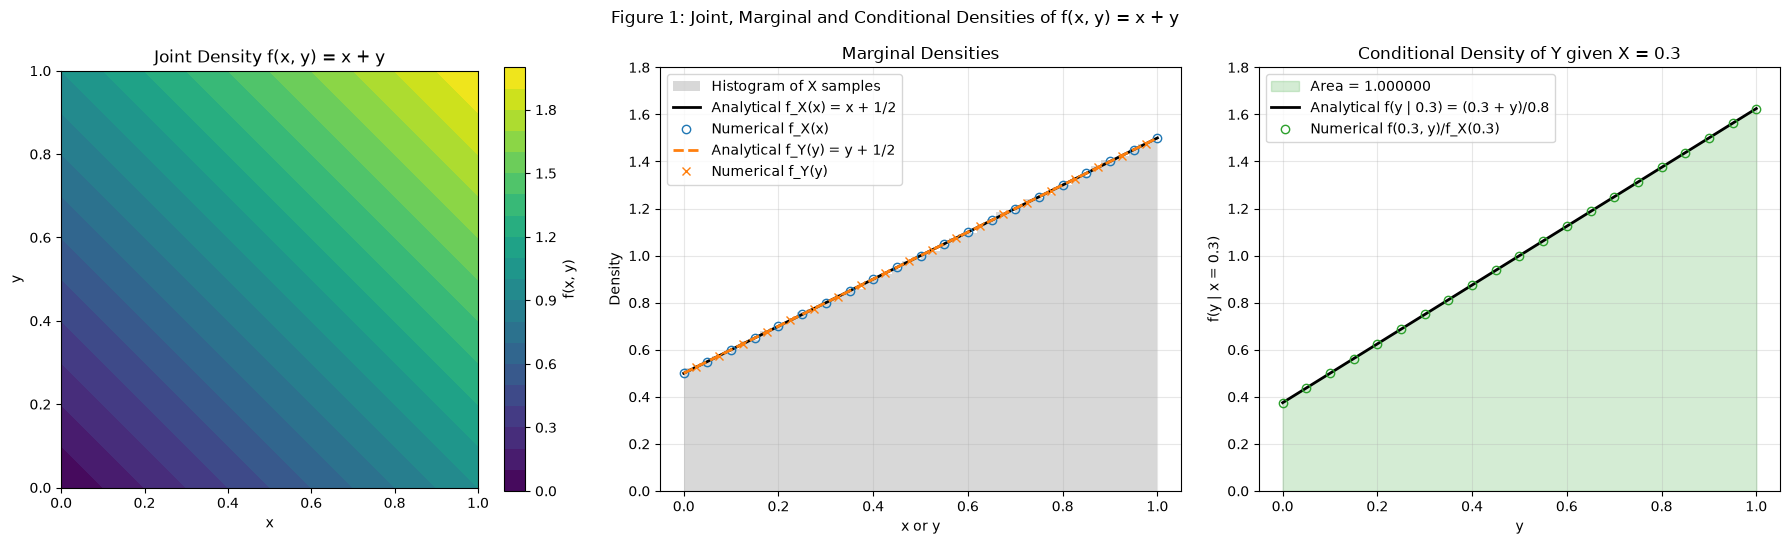

In [5]:
#Figure 1: joint density, marginals and conditional density

plt.figure(figsize=(18, 5.5))

#Joint density heatmap
plt.subplot(1, 3, 1)
plt.contourf(X_grid, Y_grid, joint_grid, levels=20, cmap="viridis")
plt.colorbar(label="f(x, y)")
plt.gca().set_aspect("equal")
plt.title("Joint Density f(x, y) = x + y")
plt.xlabel("x")
plt.ylabel("y")

#Marginals, analytical as lines and numerical as markers (every 50th grid point so the line is still visible)
plt.subplot(1, 3, 2)
plt.hist(x_samples, bins=50, range=(0, 1), density=True, alpha=0.3, color="gray", label="Histogram of X samples")
plt.plot(x_grid, marginal_x(x_grid), "black", linewidth=2, label="Analytical f_X(x) = x + 1/2")
plt.plot(x_grid[::50], fx_numerical[::50], "o", color="tab:blue", markerfacecolor="none", label="Numerical f_X(x)")
plt.plot(y_grid, marginal_y(y_grid), "--", color="tab:orange", linewidth=2, label="Analytical f_Y(y) = y + 1/2")
plt.plot(y_grid[25::50], fy_numerical[25::50], "x", color="tab:orange", label="Numerical f_Y(y)")
plt.ylim(0, 1.8)
plt.title("Marginal Densities")
plt.xlabel("x or y")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

#Conditional density at x = 0.3
plt.subplot(1, 3, 3)
plt.fill_between(y_grid, conditional_analytical, color="tab:green", alpha=0.2, label=f"Area = {conditional_integral:.6f}")
plt.plot(y_grid, conditional_analytical, "black", linewidth=2, label="Analytical f(y | 0.3) = (0.3 + y)/0.8")
plt.plot(y_grid[::50], conditional_numerical[::50], "o", color="tab:green", markerfacecolor="none", label="Numerical f(0.3, y)/f_X(0.3)")
plt.ylim(0, 1.8)
plt.title("Conditional Density of Y given X = 0.3")
plt.xlabel("y")
plt.ylabel("f(y | x = 0.3)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 1: Joint, Marginal and Conditional Densities of f(x, y) = x + y")
plt.tight_layout()
plt.show()

### Figure 1 Explanation

    The left graph depicts the joint density, which increases from 0 at the origin to 2 at the corner (1, 1). The middle graph depicts the marginal densities, and you will notice that the numerical marginals land right on the analytical lines x + 1/2 and y + 1/2 with a largest difference of 1.11e-15. Both marginals are the same because the density is symmetric in x and y. The right graph depicts the conditional density of Y given X = 0.3, which goes from 0.3750 at y = 0 to 1.6250 at y = 1 and has an area of 1.000000. The quadrature of the joint density was 1.0000000000, and every moment from quadrature matched our hand calculations with a difference of 2.58e-15 or smaller, so all of the check yourself values were reproduced.

    For rejection sampling the acceptance rate was 0.49976 with a standard error of 0.00034, which is close to the expected 1/M = 0.5. All of the sample statistics were within 3 standard errors of the exact values, for example the sample correlation was -0.089741 with a standard error of 0.001097 compared to the exact -0.090909. This shows that our rejection sampler produces samples from the correct density.

### Why is the Correlation Negative?

$$E[Y\mid X=x]=\frac{\frac{x}{2}+\frac{1}{3}}{x+\frac{1}{2}}$$

This goes from 0.6667 at $x=0$ to 0.5556 at $x=1$, and our samples show the same thing (0.6510 when $X<0.1$ and 0.5588 when $X>0.9$).

    When x is small, y makes up most of the density so Y is pulled toward large values. When x is large the density is already high for every y, so Y is spread out more evenly and its average drops, which means that a larger X goes with a smaller Y and gives the small negative correlation.

In [6]:
#Total notebook runtime
total_runtime = time.time() - T_START

print("Total notebook runtime:", round(total_runtime / 60, 2), "minutes")

#Youtube unlisted demo video
# 

Total notebook runtime: 0.03 minutes
